QUESTION 3: CLUSTERING

In [1]:
#import frameworks
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
sns.set_theme(style="whitegrid")

In [4]:
#load and inpect dataset
mall_data = r"C:\Users\Del\Downloads\Mall_Customers.csv"
df = pd.read_csv(mall_data)
print(df.columns.tolist())
df.columns = ["CustomerID", "Gender", "Age", "Income", "Spending"]

print("Dimensions:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df[["Age", "Income", "Spending"]].describe()

['CustomerID', 'Genre', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']
Dimensions: (200, 5)

Data types:
 CustomerID    int64
Gender          str
Age           int64
Income        int64
Spending      int64
dtype: object

Missing values:
 CustomerID    0
Gender        0
Age           0
Income        0
Spending      0
dtype: int64

Duplicate rows: 0


,Age,Income,Spending
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


In [5]:
#data wrangling
features = ["Age", "Income", "Spending"]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])
print("Means:", X_scaled.mean(axis=0).round(2))
print("Standard deviations:", X_scaled.std(axis=0).round(2))

Means: [-0. -0. -0.]
Standard deviations: [1. 1. 1.]


EDA

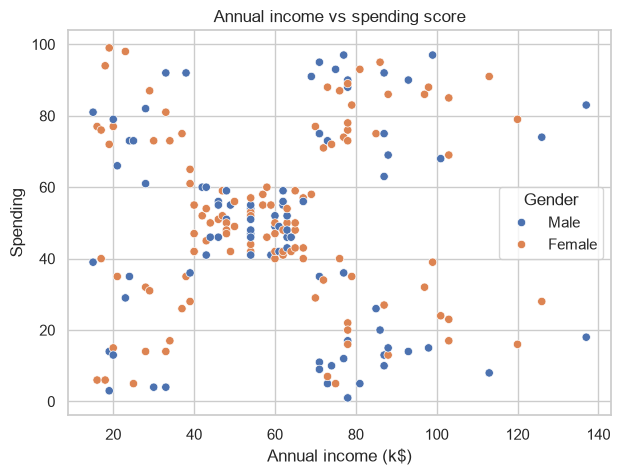

In [6]:
#scatterplot of income vs spending
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Income", y="Spending", hue="Gender")
plt.title("Annual income vs spending score")
plt.xlabel("Annual income (k$)")
plt.show()

The scatter plot shows clear groups of customers. There is a dense group in the middle (medium income and medium spending) and four groups in the corners (high or low income with high or low spending). Male and female customers appear in all groups, so gender does not separate the groups

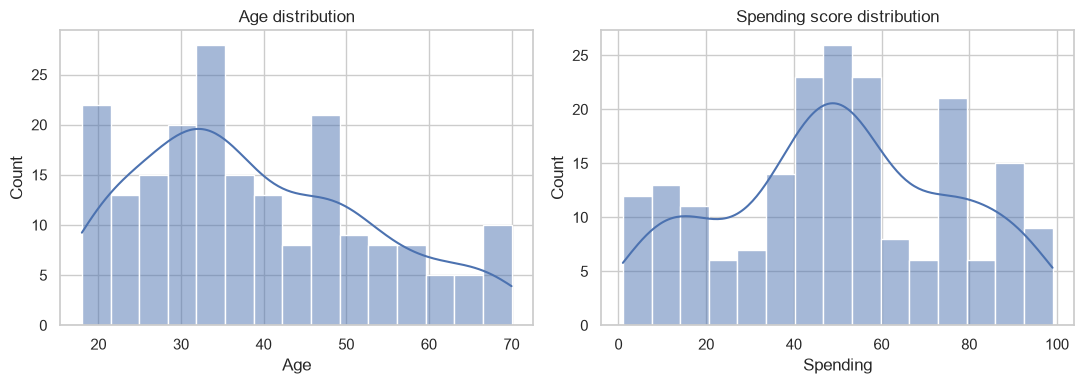

In [7]:
#distribution of age and spending score
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["Age"], bins=15, kde=True, ax=ax[0])
ax[0].set_title("Age distribution")
sns.histplot(df["Spending"], bins=15, kde=True, ax=ax[1])
ax[1].set_title("Spending score distribution")
plt.tight_layout()
plt.show()

Most customers are between 20 and 50 years old, with the most common ages around 30 to 35, and there are fewer older customers. Spending scores are concentrated in the middle (about 40 to 60), with smaller groups at the low end (below 20) and the high end (above 70).

Model Building

In [19]:
#Apply k-means
import os
os.environ["OMP_NUM_THREADS"] = "1"

import warnings
warnings.filterwarnings("ignore")

kmeans = KMeans(n_clusters=5, n_init=10, random_state=42)
df["Cluster"] = kmeans.fit_predict(X)

print("Silhouette score:", round(silhouette_score(X, df["Cluster"]), 3))
df["Cluster"].value_counts().sort_index()


Silhouette score: 0.555


Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

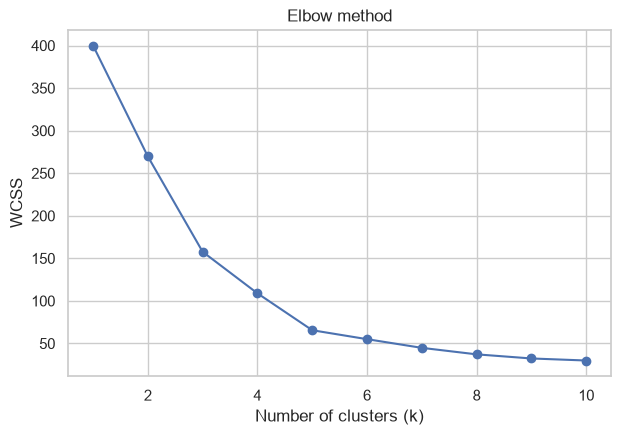

In [20]:
#elbow method

X = StandardScaler().fit_transform(df[["Income", "Spending"]])

wcss = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    wcss.append(km.inertia_)

plt.figure(figsize=(7, 4.5))
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow method")
plt.xlabel("Number of clusters (k)")
plt.ylabel("WCSS")
plt.show()

visualization and interpretation

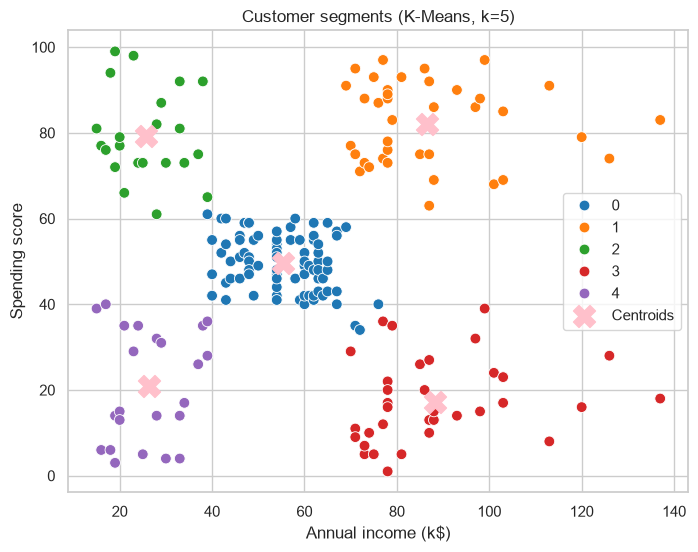

In [21]:
#plotting clusters with different colors
centers = StandardScaler().fit(df[["Income", "Spending"]]).inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="Income", y="Spending", hue="Cluster", palette="tab10", s=60)
plt.scatter(centers[:, 0], centers[:, 1], c="pink", marker="X", s=250, label="Centroids")
plt.title("Customer segments (K-Means, k=5)")
plt.xlabel("Annual income (k$)")
plt.ylabel("Spending score")
plt.legend()
plt.show()

The plot shows five clearly separated groups in different colors, with a pink X marking the center of each cluster

In [22]:
#cluster
df.groupby("Cluster").agg(Customers=("CustomerID", "count"),
                          Avg_Age=("Age", "mean"),
                          Avg_Income=("Income", "mean"),
                          Avg_Spending=("Spending", "mean")).round(1)

,Customers,Avg_Age,Avg_Income,Avg_Spending
Cluster,,,,
0,81,42.7,55.3,49.5
1,39,32.7,86.5,82.1
2,22,25.3,25.7,79.4
3,35,41.1,88.2,17.1
4,23,45.2,26.3,20.9


##Interpretation of customer segments
High income, high spending (Cluster 1, 39 customers): the best customers. Give them premium offers and rewards.
High income, low spending (Cluster 3, 35 customers): they can afford more but spend little. Targeted promotions could increase their spending.
Low income, high spending (Cluster 2, 22 customers): young, impulsive buyers who respond to discounts.
Low income, low spending (Cluster 4, 23 customers): cautious buyers and a low marketing priority.
Medium income, medium spending (Cluster 0, 81 customers): the largest group of average customers.